# Классификация пород кошек и собак по лицу

Используем упрощенный датасет [Oxford-IIIT Dataset](https://www.robots.ox.ac.uk/~vgg/data/pets/) с вырезанными лицами домашних животных. Для начала загружаем датасет:

In [1]:
!wget http://www.soshnikov.com/permanent/data/petfaces.tar.gz
!tar xfz petfaces.tar.gz
!rm petfaces.tar.gz

--2026-10-05 16:34:53--  http://www.soshnikov.com/permanent/data/petfaces.tar.gz
Resolving www.soshnikov.com (www.soshnikov.com)... 79.137.227.122
Connecting to www.soshnikov.com (www.soshnikov.com)|79.137.227.122|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 24483412 (23M) [application/x-tar]
Saving to: ‘petfaces.tar.gz’

petfaces.tar.gz     100%[===================>]  23.35M   186KB/s    in 2m 8s   

2026-10-05 16:37:02 (186 KB/s) - ‘petfaces.tar.gz’ saved [24483412/24483412]



Для визуализации списка изображений можно использовать такую функцию:

In [2]:
import matplotlib.pyplot as plt
import os
from PIL import Image
import numpy as np

def display_images(l,titles=None,fontsize=12):
    n=len(l)
    fig,ax = plt.subplots(1,n)
    for i,im in enumerate(l):
        ax[i].imshow(im)
        ax[i].axis('off')
        if titles is not None:
            ax[i].set_title(titles[i],fontsize=fontsize)
    fig.set_size_inches(fig.get_size_inches()*n)
    plt.tight_layout()
    plt.show()

## План работы

1. Загрузить изображения, посмотреть на данные и на баланс классов.
2. Разделить данные на train / validation / test **с сохранением пропорций классов** (stratified split).
3. Придумать свёрточную сеть и обучить её для двух задач:
   * кошка или собака (2 класса);
   * порода (все классы датасета).
4. Подобрать гиперпараметры (архитектура, learning rate, число нейронов, размер фильтров) по validation-части.
5. Обучить лучшую конфигурацию и посчитать на тесте: accuracy, top-3 accuracy, точность «кошки против собак», confusion matrix.

Ноутбук рассчитан на запуск в Google Colab с GPU (*Среда выполнения → Сменить среду выполнения → T4 GPU*). На CPU он тоже работает, но подбор гиперпараметров будет идти заметно дольше.

In [3]:
import random
import time

import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

SEED = 42

def seed_everything(seed=SEED):
    """Фиксируем генераторы случайных чисел, чтобы результаты воспроизводились."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_everything()
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Устройство:', device)

Устройство: cuda


## 1. Загрузка и просмотр данных

Каждая порода лежит в своей папке внутри `petfaces`. Имя папки начинается с `cat_` или `dog_` — по этому префиксу определяем вид животного.

Картинки маленькие, и их немного (от 59 до 182 на породу, всего 3211), поэтому загружаем весь датасет в память и сразу приводим к одному размеру `IMG_SIZE x IMG_SIZE`.

In [4]:
DATA_DIR = 'petfaces'
IMG_SIZE = 64

classes = sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)))

images, labels = [], []
for class_id, cls in enumerate(classes):
    for fname in sorted(os.listdir(os.path.join(DATA_DIR, cls))):
        try:
            img = Image.open(os.path.join(DATA_DIR, cls, fname)).convert('RGB')
        except Exception:
            continue  # в папке оказался не графический файл
        images.append(img.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))
        labels.append(class_id)
labels = np.array(labels)

def is_cat(class_name):
    if class_name.startswith('cat_'):
        return True
    if class_name.startswith('dog_'):
        return False
    return class_name[0].isupper()  # запасной вариант: в Oxford Pets породы кошек пишутся с заглавной буквы

# species[i] = 0, если класс i - кошка, и 1, если собака
species = np.array([0 if is_cat(c) else 1 for c in classes])
SPECIES_NAMES = ['cat', 'dog']

num_classes = len(classes)
print(f'Изображений: {len(images)}, классов: {num_classes} '
      f'(кошек: {(species == 0).sum()}, собак: {(species == 1).sum()})')

Изображений: 3211, классов: 35 (кошек: 12, собак: 23)


cat_Abyssinian


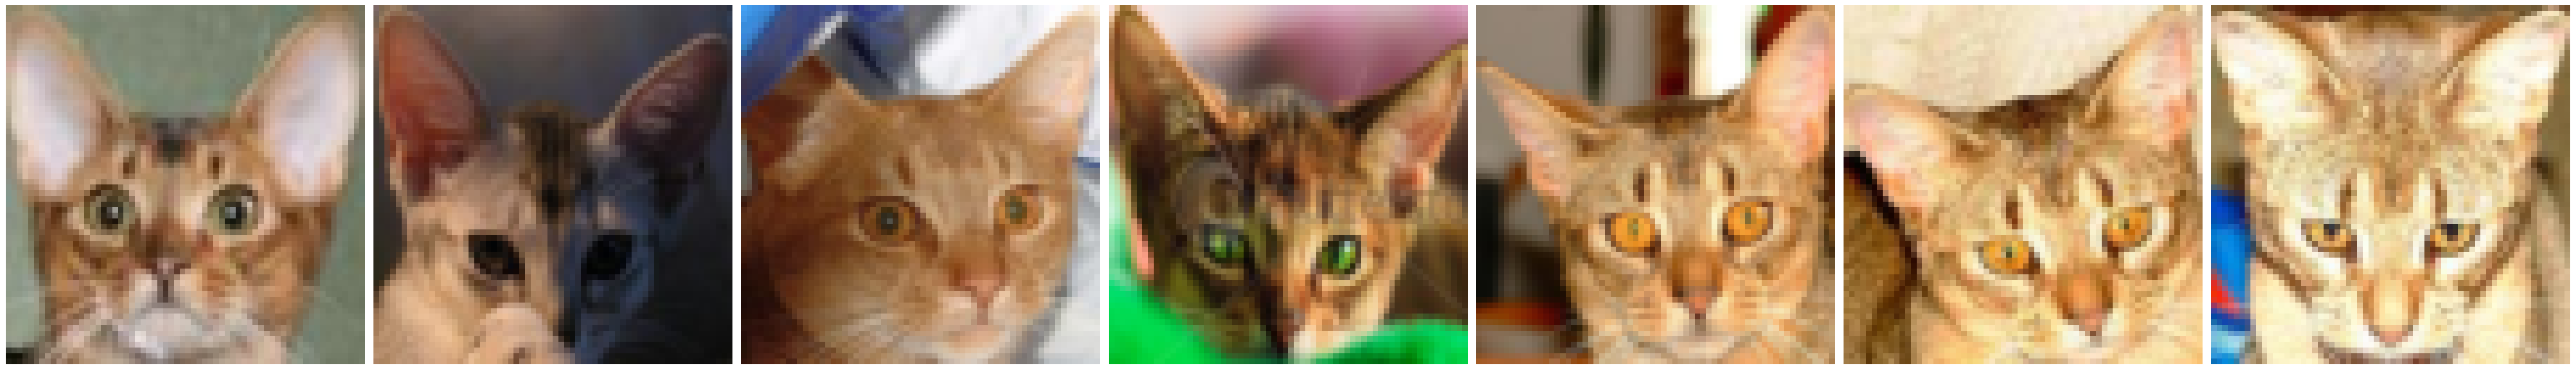

cat_Bengal


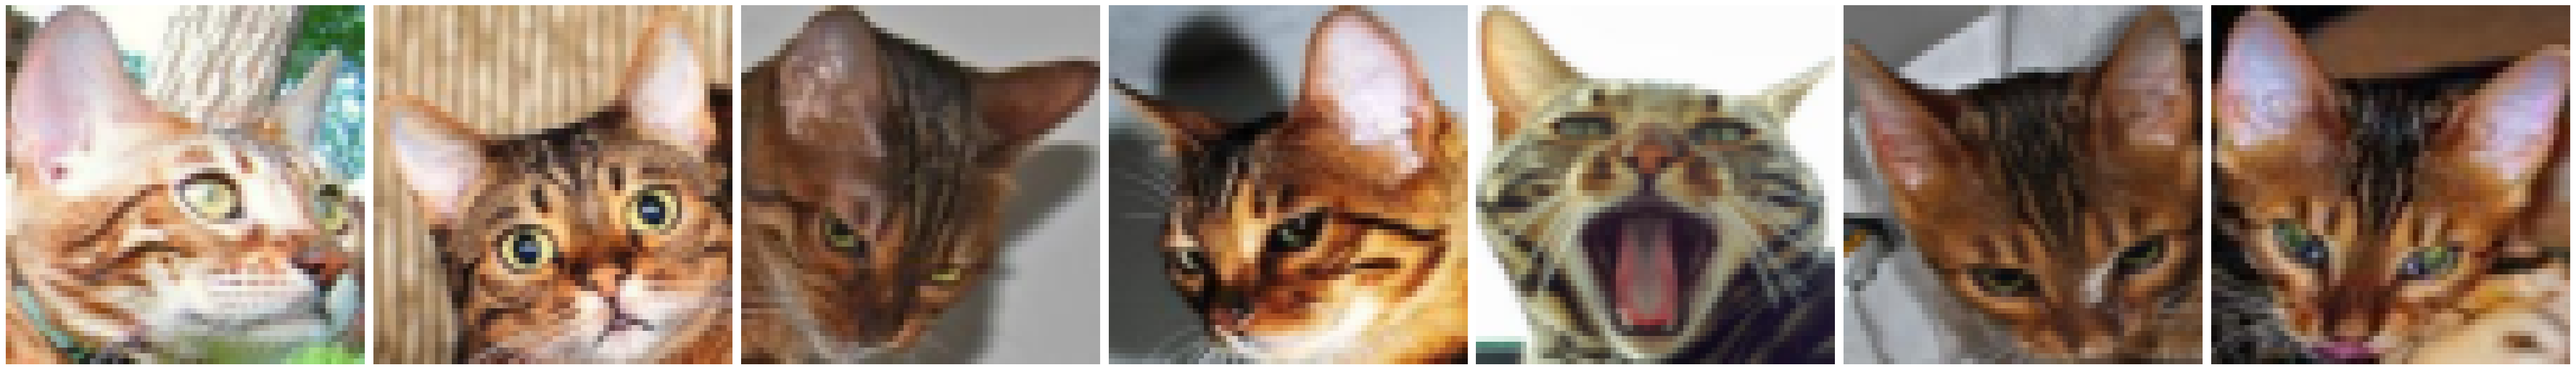

cat_Birman


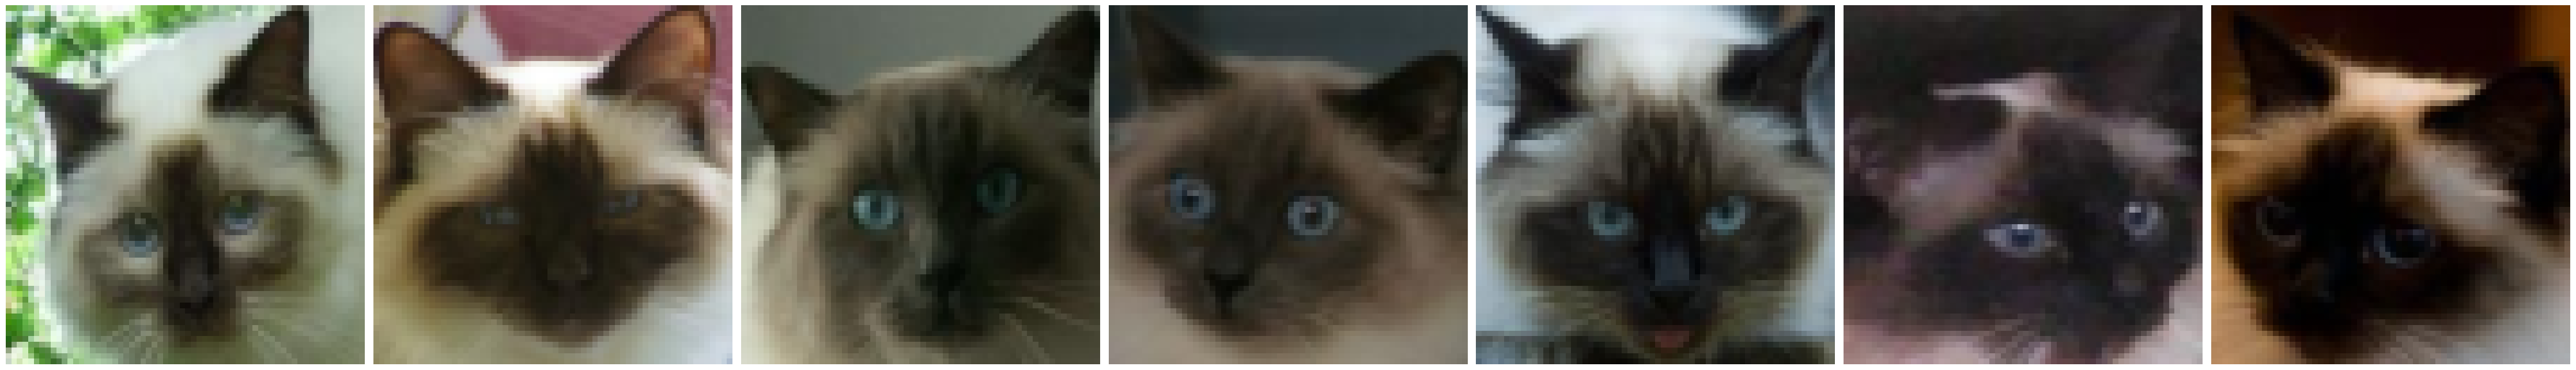

In [5]:
# Несколько примеров для первых классов
for cls_id in range(3):
    ids = np.where(labels == cls_id)[0][:7]
    print(classes[cls_id])
    display_images([images[i] for i in ids])

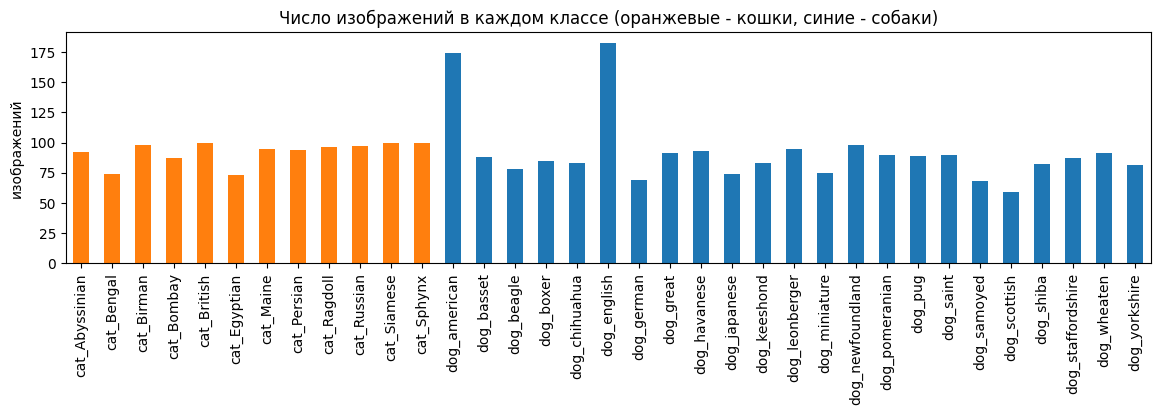

Минимум в классе: 59 | максимум: 182


In [6]:
# Баланс классов
counts = pd.Series(labels).map(lambda i: classes[i]).value_counts().sort_index()
counts.plot.bar(figsize=(14, 3), color=['tab:orange' if is_cat(c) else 'tab:blue' for c in counts.index])
plt.title('Число изображений в каждом классе (оранжевые - кошки, синие - собаки)')
plt.ylabel('изображений')
plt.show()
print('Минимум в классе:', counts.min(), '| максимум:', counts.max())

## 2. Разделение на train / validation / test

* **test** (20%) — откладываем сразу и используем только для итоговых цифр;
* **validation** (20% от оставшегося) — на нём сравниваем гиперпараметры;
* **train** — всё остальное.

Параметр `stratify` у `train_test_split` гарантирует, что доля каждой породы во всех частях одинаковая.

In [7]:
all_idx = np.arange(len(labels))
trainval_idx, test_idx = train_test_split(all_idx, test_size=0.2, stratify=labels, random_state=SEED)
train_idx, val_idx = train_test_split(trainval_idx, test_size=0.2, stratify=labels[trainval_idx],
                                      random_state=SEED)
print(f'train: {len(train_idx)}, validation: {len(val_idx)}, test: {len(test_idx)}')

# Проверяем, что пропорции классов сохранились
split_table = pd.DataFrame({
    'всего': np.bincount(labels, minlength=num_classes),
    'train': np.bincount(labels[train_idx], minlength=num_classes),
    'val': np.bincount(labels[val_idx], minlength=num_classes),
    'test': np.bincount(labels[test_idx], minlength=num_classes),
}, index=classes)
split_table['доля test'] = (split_table['test'] / split_table['всего']).round(3)
display(split_table)

train: 2054, validation: 514, test: 643


,всего,train,val,test,доля test
cat_Abyssinian,92,59,15,18,0.196
cat_Bengal,74,47,12,15,0.203
cat_Birman,98,62,16,20,0.204
cat_Bombay,87,56,14,17,0.195
cat_British,100,64,16,20,0.200
cat_Egyptian,73,46,12,15,0.205
cat_Maine,95,61,15,19,0.200
cat_Persian,94,60,15,19,0.202
cat_Ragdoll,96,62,15,19,0.198
cat_Russian,97,62,16,19,0.196


## 3. Предобработка и загрузчики данных

* Пиксели переводим в тензор и нормируем в диапазон `[-1, 1]`.
* Для обучающей части добавляем **аугментации** (отражение, небольшой поворот/сдвиг/масштаб, изменение яркости и цвета). Данных мало, и без аугментаций сеть быстро переобучается.
* Для validation и test аугментаций нет.

Размер батча изображений: (64, 3, 64, 64)
Размер батча меток: (64,) | примеры меток: [25, 12, 27, 20, 12, 27, 17, 26]


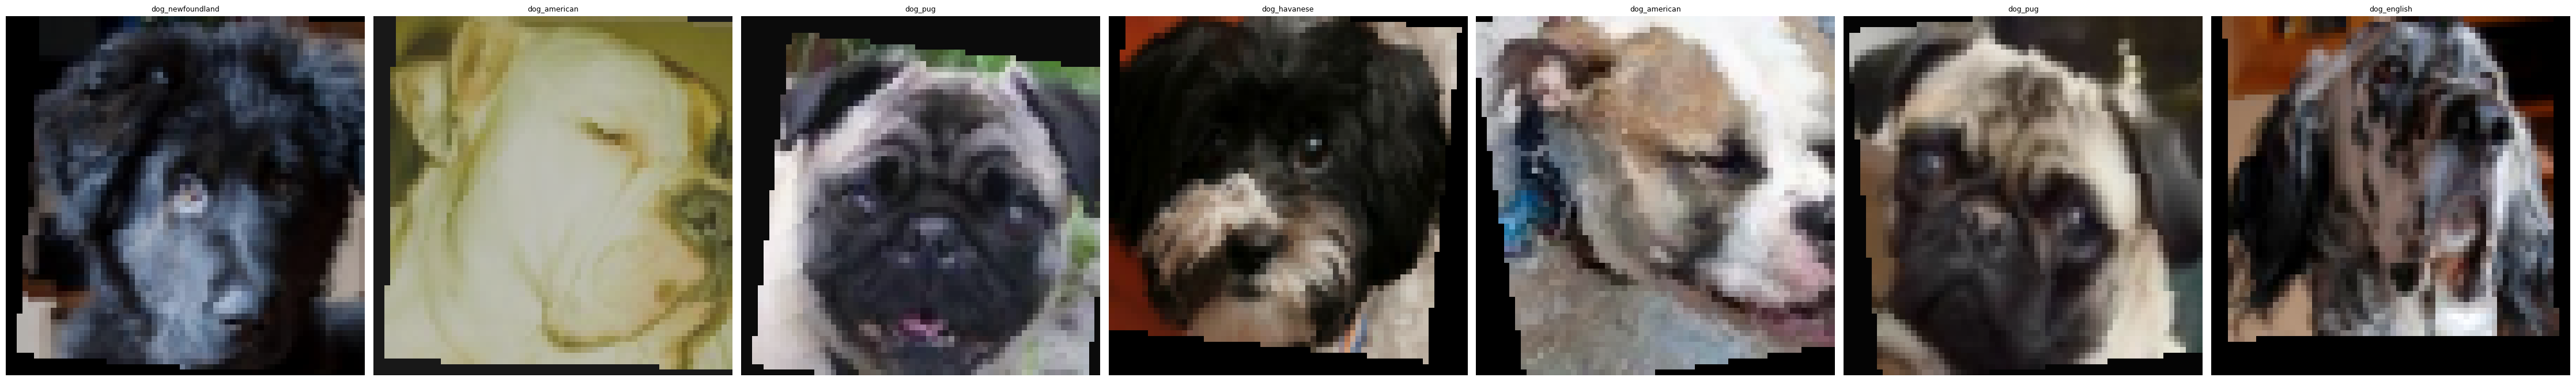

In [8]:
normalize = transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])

train_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=10, translate=(0.08, 0.08), scale=(0.9, 1.1)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    normalize,
])
eval_tf = transforms.Compose([transforms.ToTensor(), normalize])


class FaceDataset(Dataset):
    """Подмножество изображений по списку индексов. binary=True - метки 'кошка/собака' вместо породы."""

    def __init__(self, idx, transform, binary=False):
        self.idx, self.transform, self.binary = idx, transform, binary

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        j = self.idx[i]
        y = species[labels[j]] if self.binary else labels[j]
        return self.transform(images[j]), int(y)


def make_loaders(fit_idx, eval_idx, binary=False, batch_size=64):
    train_dl = DataLoader(FaceDataset(fit_idx, train_tf, binary), batch_size=batch_size,
                          shuffle=True, drop_last=True, num_workers=2)
    eval_dl = DataLoader(FaceDataset(eval_idx, eval_tf, binary), batch_size=256, num_workers=2)
    return train_dl, eval_dl


train_dl, val_dl = make_loaders(train_idx, val_idx)
x, y = next(iter(train_dl))
print('Размер батча изображений:', tuple(x.shape))
print('Размер батча меток:', tuple(y.shape), '| примеры меток:', y[:8].tolist())

# Как выглядят изображения после аугментаций
display_images([(x[i].permute(1, 2, 0) * 0.5 + 0.5).clip(0, 1) for i in range(7)],
               titles=[classes[i] for i in y[:7]], fontsize=9)

## 4. Архитектура сети

Сеть собрана из одинаковых блоков в стиле VGG:

`[Conv → BatchNorm → ReLU] × 2 → MaxPool`

* После каждого блока размер картинки уменьшается вдвое, а число каналов растёт («пирамида»).
* `BatchNorm` ускоряет и стабилизирует обучение.
* После свёрточной части — глобальное усреднение (`AdaptiveAvgPool2d`), `Dropout` и два полносвязных слоя.
* Последний слой без активации: `cross_entropy` сама применяет softmax.

Все важные размеры вынесены в параметры конструктора, чтобы их можно было перебирать при подборе гиперпараметров:
`channels` — число фильтров в каждом блоке (и число блоков), `kernel` — размер фильтра, `hidden` — число нейронов скрытого полносвязного слоя, `dropout`.

In [9]:
class PetCNN(nn.Module):
    def __init__(self, n_classes, channels=(32, 64, 128, 256), kernel=3, hidden=256, dropout=0.3):
        super().__init__()
        layers, c_in = [], 3
        for c_out in channels:
            layers += [
                nn.Conv2d(c_in, c_out, kernel, padding=kernel // 2, bias=False),
                nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
                nn.Conv2d(c_out, c_out, kernel, padding=kernel // 2, bias=False),
                nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
            ]
            c_in = c_out
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Dropout(dropout), nn.Linear(c_in, hidden), nn.ReLU(inplace=True),
            nn.Dropout(dropout), nn.Linear(hidden, n_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def count_params(model):
    return sum(p.numel() for p in model.parameters())


model = PetCNN(num_classes)
print(model)
print(f'Параметров: {count_params(model) / 1e6:.2f} млн')
print('Размер выхода для батча из 4 картинок:', tuple(model(torch.zeros(4, 3, IMG_SIZE, IMG_SIZE)).shape))

PetCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU(inplace=True)
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU(inplace=True)
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation

## 5. Функции обучения и оценки

* `run_epoch` — один проход по данным (с обновлением весов, если передан оптимизатор);
* `fit` — обучение на заданное число эпох, оптимизатор AdamW, learning rate плавно уменьшается по косинусу;
* `predict` — выходы сети (логиты) и правильные ответы для всего загрузчика;
* `topk_accuracy` — доля примеров, где правильный класс попал в `k` самых вероятных.

In [10]:
def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    loss_sum, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = F.cross_entropy(out, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            loss_sum += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            total += len(y)
    return loss_sum / total, correct / total


def fit(model, train_dl, eval_dl, epochs=30, lr=1e-3, weight_decay=1e-4, verbose=True):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    history = {'train_loss': [], 'train_acc': [], 'eval_loss': [], 'eval_acc': []}
    for epoch in range(1, epochs + 1):
        train_loss, train_acc = run_epoch(model, train_dl, optimizer)
        eval_loss, eval_acc = run_epoch(model, eval_dl)
        scheduler.step()
        for key, value in zip(history, (train_loss, train_acc, eval_loss, eval_acc)):
            history[key].append(value)
        if verbose and (epoch % 5 == 0 or epoch == 1 or epoch == epochs):
            print(f'эпоха {epoch:3d}: train loss {train_loss:.3f}, acc {train_acc:.3f} | '
                  f'eval loss {eval_loss:.3f}, acc {eval_acc:.3f}')
    return history


@torch.no_grad()
def predict(model, loader):
    model.eval()
    outputs, targets = [], []
    for x, y in loader:
        outputs.append(model(x.to(device)).cpu())
        targets.append(y)
    return torch.cat(outputs), torch.cat(targets)


def topk_accuracy(logits, targets, k):
    topk = logits.topk(k, dim=1).indices              # k самых вероятных классов для каждого примера
    return (topk == targets[:, None]).any(dim=1).float().mean().item()


def plot_history(history, title, eval_name='validation'):
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    for a, metric in zip(ax, ('loss', 'acc')):
        a.plot(history[f'train_{metric}'], label='train')
        a.plot(history[f'eval_{metric}'], label=eval_name)
        a.set_xlabel('эпоха')
        a.set_title(f'{title}: {metric}')
        a.legend()
        a.grid(alpha=0.3)
    plt.show()

## 6. Задача 1: кошка или собака (бинарная классификация)

Задача простая, поэтому берём сеть поменьше (3 блока). Классов два, выход сети — 2 нейрона.

эпоха   1: train loss 0.651, acc 0.637 | eval loss 0.652, acc 0.605
эпоха   5: train loss 0.442, acc 0.801 | eval loss 0.408, acc 0.798
эпоха  10: train loss 0.275, acc 0.897 | eval loss 0.724, acc 0.763
эпоха  15: train loss 0.157, acc 0.939 | eval loss 0.182, acc 0.924
эпоха  20: train loss 0.134, acc 0.947 | eval loss 0.150, acc 0.953


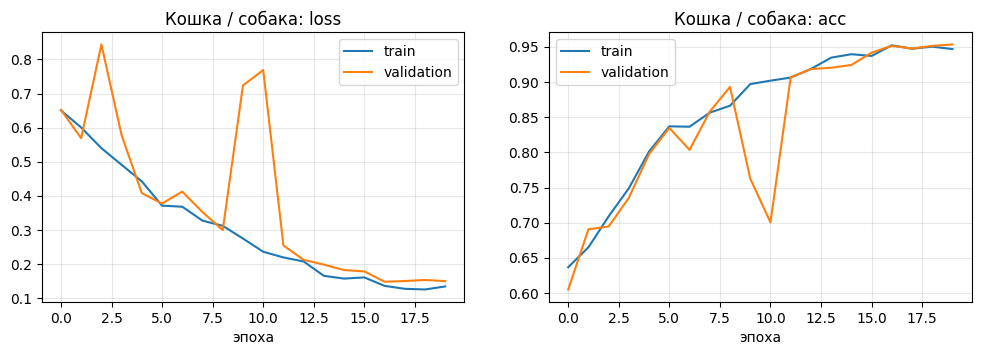

In [11]:
seed_everything()
bin_train_dl, bin_val_dl = make_loaders(train_idx, val_idx, binary=True)
bin_model = PetCNN(2, channels=(32, 64, 128), hidden=128).to(device)
bin_history = fit(bin_model, bin_train_dl, bin_val_dl, epochs=20, lr=1e-3)
plot_history(bin_history, 'Кошка / собака')

Точность бинарного классификатора на тесте: 0.9596


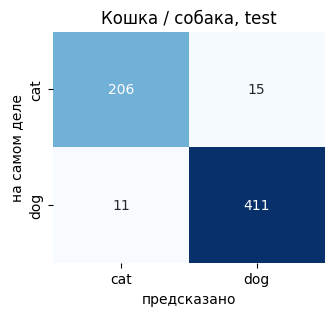

In [12]:
_, bin_test_dl = make_loaders(train_idx, test_idx, binary=True)
bin_logits, bin_targets = predict(bin_model, bin_test_dl)
bin_pred = bin_logits.argmax(1)
binary_net_acc = (bin_pred == bin_targets).float().mean().item()
print(f'Точность бинарного классификатора на тесте: {binary_net_acc:.4f}')

cm_bin = confusion_matrix(bin_targets.numpy(), bin_pred.numpy())
plt.figure(figsize=(3.5, 3))
sns.heatmap(cm_bin, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=SPECIES_NAMES, yticklabels=SPECIES_NAMES)
plt.xlabel('предсказано')
plt.ylabel('на самом деле')
plt.title('Кошка / собака, test')
plt.show()

## 7. Задача 2: определение породы — базовая модель

Сначала обучаем сеть с параметрами по умолчанию, чтобы получить точку отсчёта и посмотреть на кривые обучения. По разрыву между train и validation видно, насколько сеть переобучается.

эпоха   1: train loss 3.399, acc 0.073 | eval loss 3.259, acc 0.105
эпоха   5: train loss 2.837, acc 0.181 | eval loss 2.718, acc 0.198
эпоха  10: train loss 2.154, acc 0.321 | eval loss 2.185, acc 0.356
эпоха  15: train loss 1.695, acc 0.462 | eval loss 2.113, acc 0.360
эпоха  20: train loss 1.282, acc 0.582 | eval loss 1.539, acc 0.521
эпоха  25: train loss 1.038, acc 0.663 | eval loss 1.135, acc 0.634
эпоха  30: train loss 0.918, acc 0.712 | eval loss 1.070, acc 0.665


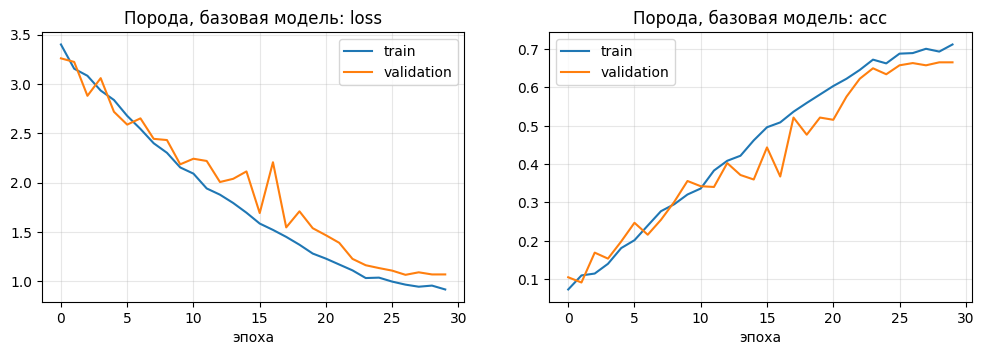

Базовая модель, точность на validation: 0.6654


In [13]:
seed_everything()
base_model = PetCNN(num_classes).to(device)
base_history = fit(base_model, train_dl, val_dl, epochs=30, lr=1e-3)
plot_history(base_history, 'Порода, базовая модель')
baseline_val_acc = base_history['eval_acc'][-1]
print(f'Базовая модель, точность на validation: {baseline_val_acc:.4f}')

## 8. Оптимизация гиперпараметров

Перебираем случайные сочетания (random search) из сетки:

| гиперпараметр | что меняет | варианты |
|---|---|---|
| `channels` | архитектура: глубина сети и число фильтров | 3, 4 или 5 блоков, узкие и широкие |
| `kernel` | размер фильтров свёртки | 3 или 5 |
| `hidden` | число нейронов скрытого слоя | 128, 256, 512 |
| `lr` | learning rate | 3e-4, 1e-3, 3e-3 |
| `dropout` | сила регуляризации | 0.2, 0.4 |

Каждый вариант обучается одинаковое число эпох на **train** и сравнивается по точности на **validation**. Тестовая часть в подборе не участвует — иначе итоговая оценка была бы завышенной.

Случайный поиск выбран потому, что полная сетка — это 4·2·3·3·2 = 144 варианта, а случайная выборка из неё даёт хорошее представление о влиянии параметров за разумное время. Число попыток задаётся в `N_TRIALS`.

In [14]:
search_space = {
    'channels': [(32, 64, 128), (32, 64, 128, 256), (64, 128, 256, 512), (32, 64, 128, 256, 512)],
    'kernel': [3, 5],
    'hidden': [128, 256, 512],
    'lr': [3e-4, 1e-3, 3e-3],
    'dropout': [0.2, 0.4],
}
N_TRIALS = 12        # сколько конфигураций попробовать
SEARCH_EPOCHS = 15   # эпох на одну конфигурацию

rng = random.Random(SEED)
configs = []
while len(configs) < N_TRIALS:
    cfg = {name: rng.choice(options) for name, options in search_space.items()}
    if cfg not in configs:
        configs.append(cfg)

trials = []
for n, cfg in enumerate(configs, 1):
    seed_everything()
    model = PetCNN(num_classes, cfg['channels'], cfg['kernel'], cfg['hidden'], cfg['dropout']).to(device)
    start = time.time()
    history = fit(model, train_dl, val_dl, epochs=SEARCH_EPOCHS, lr=cfg['lr'], verbose=False)
    trials.append({**cfg,
                   'параметров, млн': round(count_params(model) / 1e6, 2),
                   'train_acc': round(history['train_acc'][-1], 4),
                   'val_acc': round(history['eval_acc'][-1], 4),
                   'время, с': round(time.time() - start)})
    print(f'[{n}/{N_TRIALS}] {cfg} -> val_acc = {trials[-1]["val_acc"]:.4f}')

search_results = pd.DataFrame(trials).sort_values('val_acc', ascending=False).reset_index(drop=True)
display(search_results)

[1/12] {'channels': (32, 64, 128), 'kernel': 3, 'hidden': 512, 'lr': 0.001, 'dropout': 0.2} -> val_acc = 0.4241
[2/12] {'channels': (32, 64, 128, 256), 'kernel': 3, 'hidden': 512, 'lr': 0.0003, 'dropout': 0.2} -> val_acc = 0.5798
[3/12] {'channels': (32, 64, 128, 256, 512), 'kernel': 3, 'hidden': 128, 'lr': 0.0003, 'dropout': 0.2} -> val_acc = 0.7023
[4/12] {'channels': (32, 64, 128, 256), 'kernel': 3, 'hidden': 512, 'lr': 0.0003, 'dropout': 0.4} -> val_acc = 0.4728
[5/12] {'channels': (32, 64, 128, 256), 'kernel': 5, 'hidden': 512, 'lr': 0.001, 'dropout': 0.2} -> val_acc = 0.4377
[6/12] {'channels': (32, 64, 128, 256), 'kernel': 5, 'hidden': 256, 'lr': 0.001, 'dropout': 0.2} -> val_acc = 0.4533
[7/12] {'channels': (32, 64, 128, 256), 'kernel': 5, 'hidden': 128, 'lr': 0.0003, 'dropout': 0.4} -> val_acc = 0.4767
[8/12] {'channels': (32, 64, 128), 'kernel': 5, 'hidden': 256, 'lr': 0.003, 'dropout': 0.4} -> val_acc = 0.2490
[9/12] {'channels': (32, 64, 128), 'kernel': 5, 'hidden': 512, 'l

,channels,kernel,hidden,lr,dropout,"параметров, млн",train_acc,val_acc,"время, с"
0,"(32, 64, 128, 256, 512)",3,128,0.0003,0.2,4.78,0.7666,0.7023,34
1,"(32, 64, 128, 256)",3,512,0.0003,0.2,1.32,0.5874,0.5798,34
2,"(64, 128, 256, 512)",3,128,0.0003,0.4,4.76,0.4009,0.5136,45
3,"(32, 64, 128, 256)",5,128,0.0003,0.4,3.29,0.3979,0.4767,51
4,"(32, 64, 128, 256)",3,512,0.0003,0.4,1.32,0.4419,0.4728,35
5,"(32, 64, 128, 256)",5,256,0.0010,0.2,3.33,0.4277,0.4533,51
6,"(32, 64, 128, 256)",5,512,0.0010,0.2,3.41,0.4546,0.4377,50
7,"(32, 64, 128)",3,512,0.0010,0.2,0.37,0.3867,0.4241,38
8,"(32, 64, 128)",5,512,0.0003,0.4,0.88,0.2939,0.3327,38
9,"(32, 64, 128, 256)",3,128,0.0030,0.2,1.21,0.3140,0.3249,34


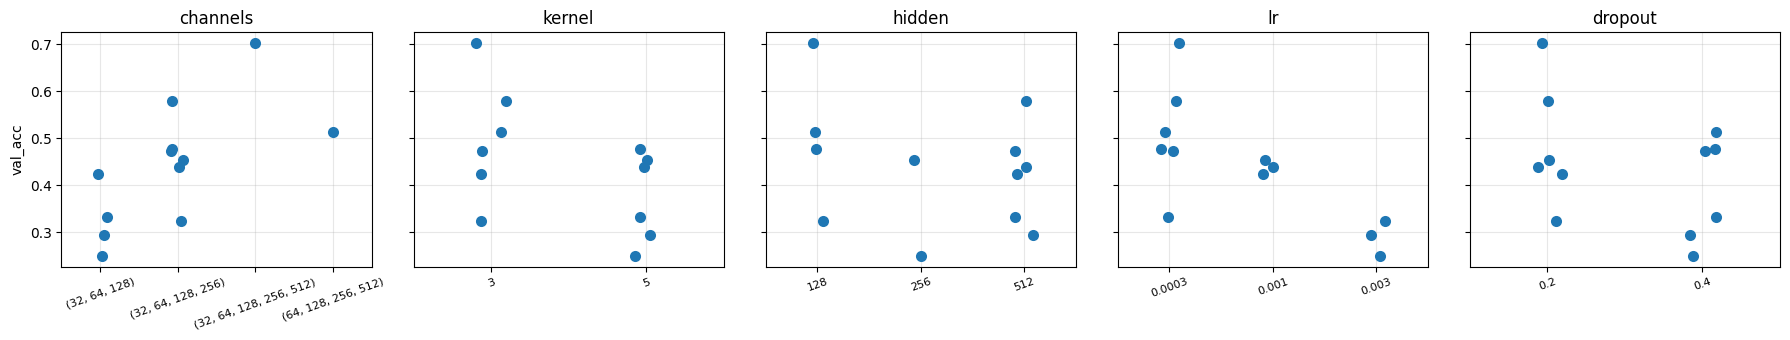

Лучшая конфигурация: {'channels': (32, 64, 128, 256, 512), 'kernel': 3, 'hidden': 128, 'lr': 0.0003, 'dropout': 0.2}
Её точность на validation: 0.7023 (базовая модель: 0.6654 за 30 эпох)


In [15]:
# Как каждый гиперпараметр связан с точностью на validation (каждая точка - одна конфигурация)
fig, ax = plt.subplots(1, len(search_space), figsize=(18, 3.5), sharey=True)
for a, name in zip(ax, search_space):
    values = search_results[name].astype(str)
    sns.stripplot(x=values, y=search_results['val_acc'], ax=a, size=8, order=sorted(values.unique()))
    a.set_title(name)
    a.set_xlabel('')
    a.tick_params(axis='x', rotation=20, labelsize=8)
    a.grid(alpha=0.3)
ax[0].set_ylabel('val_acc')
plt.tight_layout()
plt.show()

best_trial = max(trials, key=lambda t: t['val_acc'])
best_cfg = {name: best_trial[name] for name in search_space}
best_val_acc = best_trial['val_acc']
print('Лучшая конфигурация:', best_cfg)
print(f'Её точность на validation: {best_val_acc:.4f} (базовая модель: {baseline_val_acc:.4f} за 30 эпох)')

## 9. Итоговая модель

Лучшую конфигурацию обучаем заново, уже на объединении train + validation (данных мало, каждая картинка на счету) и дольше. Кривая «test» на графике нужна только для наглядности — никаких решений по ней не принимается.

эпоха   1: train loss 3.353, acc 0.096 | eval loss 3.501, acc 0.068
эпоха   5: train loss 1.838, acc 0.447 | eval loss 1.906, acc 0.451
эпоха  10: train loss 1.053, acc 0.675 | eval loss 1.342, acc 0.600
эпоха  15: train loss 0.628, acc 0.802 | eval loss 1.010, acc 0.694
эпоха  20: train loss 0.380, acc 0.884 | eval loss 0.890, acc 0.737
эпоха  25: train loss 0.216, acc 0.937 | eval loss 0.771, acc 0.773
эпоха  30: train loss 0.120, acc 0.975 | eval loss 0.657, acc 0.813
эпоха  35: train loss 0.093, acc 0.980 | eval loss 0.659, acc 0.816
эпоха  40: train loss 0.084, acc 0.983 | eval loss 0.640, acc 0.821


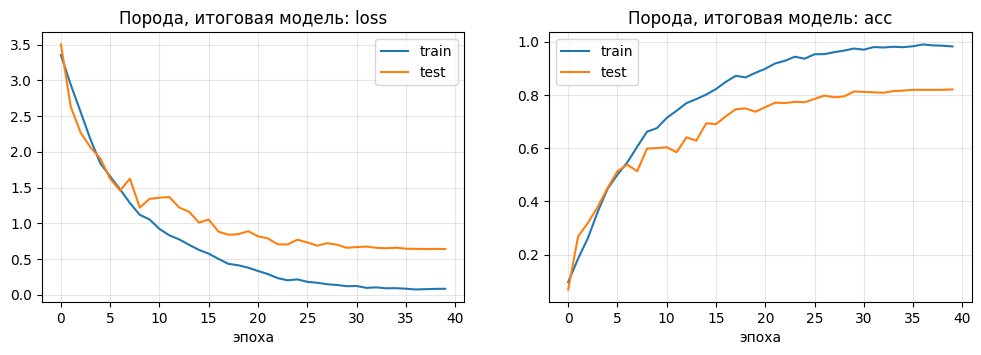

In [16]:
FINAL_EPOCHS = 40

seed_everything()
final_train_dl, test_dl = make_loaders(trainval_idx, test_idx)
final_model = PetCNN(num_classes, best_cfg['channels'], best_cfg['kernel'],
                     best_cfg['hidden'], best_cfg['dropout']).to(device)
final_history = fit(final_model, final_train_dl, test_dl, epochs=FINAL_EPOCHS, lr=best_cfg['lr'])
plot_history(final_history, 'Порода, итоговая модель', eval_name='test')

## 10. Результаты на тестовой выборке

Считаем:

* **accuracy** — доля правильно определённых пород;
* **top-3 accuracy** — правильная порода среди трёх самых вероятных;
* **кошки против собак** — берём предсказанную породу и смотрим только на то, кошка это или собака. Это можно сравнить с отдельной бинарной сетью из раздела 6.

In [17]:
logits, targets = predict(final_model, test_dl)
pred = logits.argmax(1)

breed_acc = (pred == targets).float().mean().item()
top3_acc = topk_accuracy(logits, targets, 3)

species_t = torch.tensor(species)
binary_from_breed_acc = (species_t[pred] == species_t[targets]).float().mean().item()

print(f'Точность определения породы (top-1): {breed_acc:.4f}')
print(f'Top-3 accuracy:                      {top3_acc:.4f}')
print(f'Кошки против собак (через породу):   {binary_from_breed_acc:.4f}')
print(f'Кошки против собак (бинарная сеть):  {binary_net_acc:.4f}')
print(f'Случайное угадывание породы:         {1 / num_classes:.4f}')

Точность определения породы (top-1): 0.8212
Top-3 accuracy:                      0.9456
Кошки против собак (через породу):   0.9844
Кошки против собак (бинарная сеть):  0.9596
Случайное угадывание породы:         0.0286


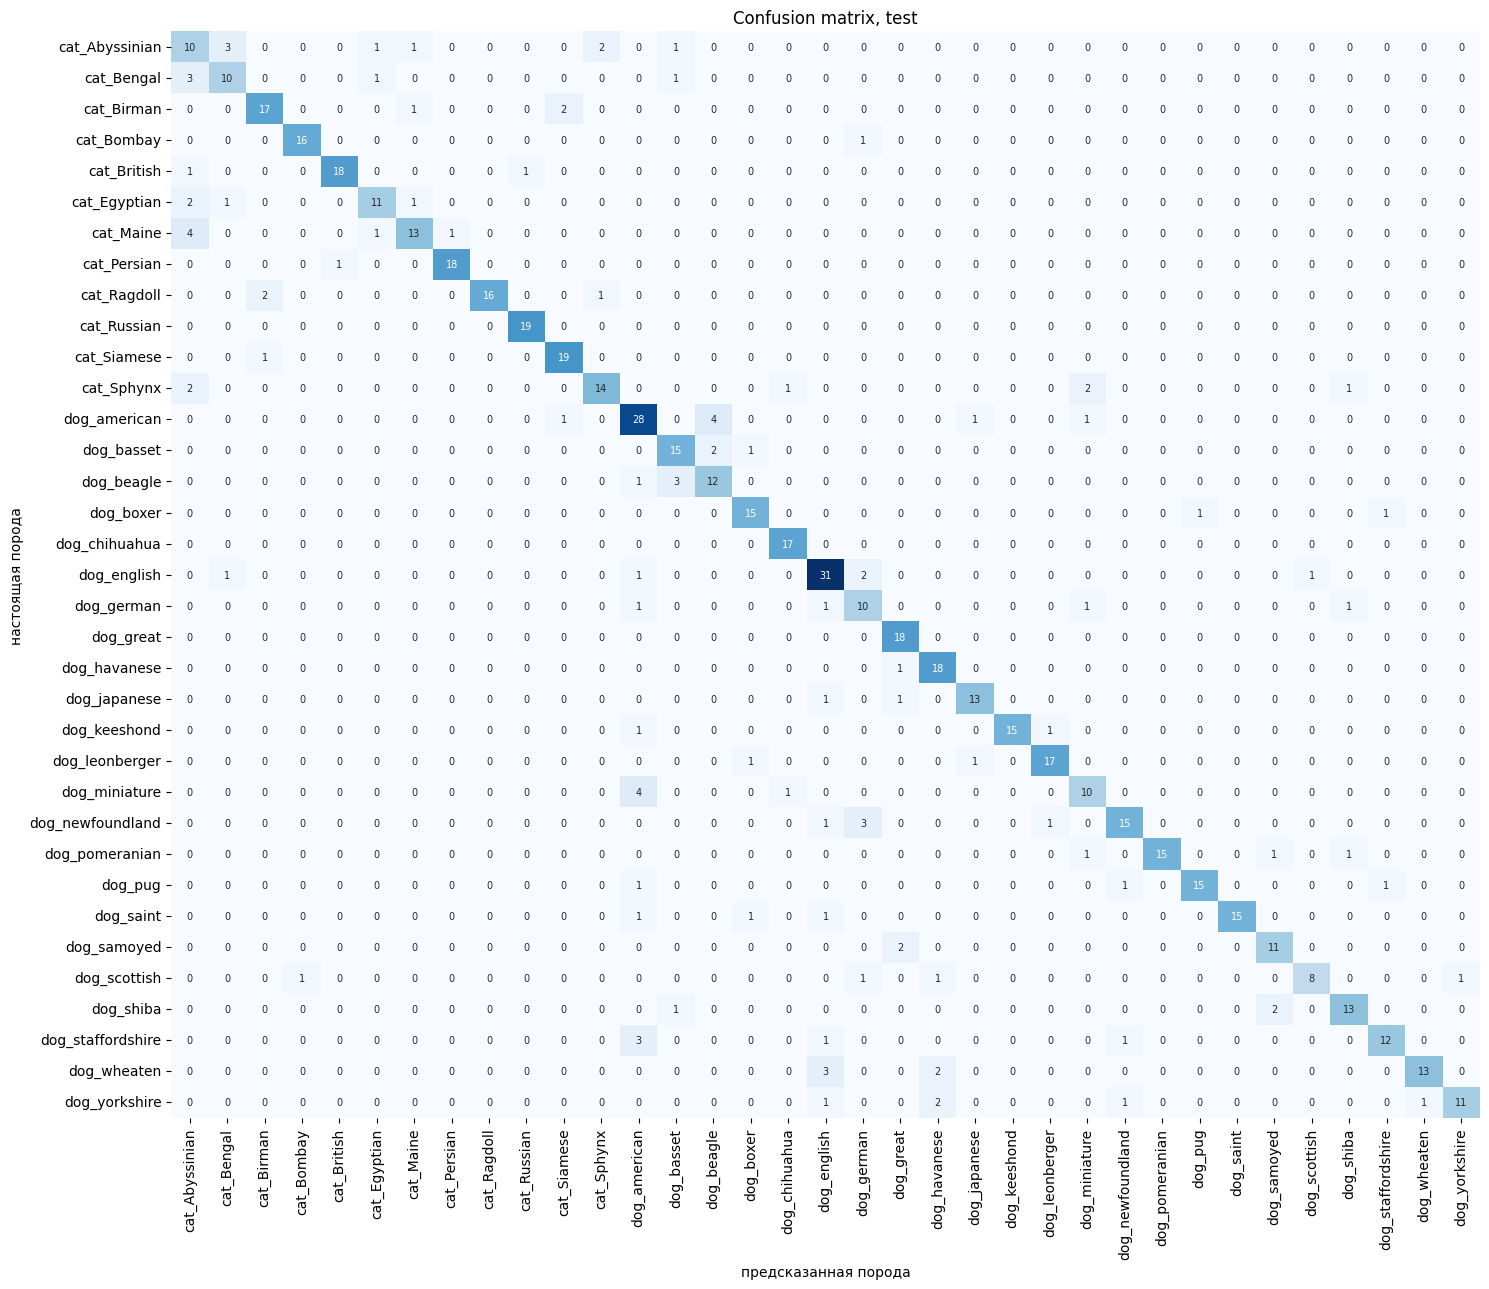

In [18]:
# Confusion matrix: строка - настоящая порода, столбец - предсказанная
cm = confusion_matrix(targets.numpy(), pred.numpy(), labels=np.arange(num_classes))
plt.figure(figsize=(15, 13))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=classes, yticklabels=classes, annot_kws={'size': 7})
plt.xlabel('предсказанная порода')
plt.ylabel('настоящая порода')
plt.title('Confusion matrix, test')
plt.tight_layout()
plt.show()

In [19]:
# Какие породы путаются чаще всего и какие распознаются лучше/хуже всего
errors = cm.copy()
np.fill_diagonal(errors, 0)
order = np.argsort(errors, axis=None)[::-1][:10]
rows, cols = np.unravel_index(order, errors.shape)
keep = errors[rows, cols] > 0                     # не показываем пары, которые ни разу не перепутались
rows, cols = rows[keep], cols[keep]
confused = pd.DataFrame({'настоящая порода': [classes[i] for i in rows],
                         'предсказана как': [classes[j] for j in cols],
                         'сколько раз': errors[rows, cols]})
display(confused)

per_class = pd.Series(cm.diagonal() / cm.sum(axis=1), index=classes).sort_values()
print('Хуже всего распознаются:')
print(per_class.head(5).round(3).to_string())
print('\nЛучше всего распознаются:')
print(per_class.tail(5).round(3).to_string())

,настоящая порода,предсказана как,сколько раз
0,dog_american,dog_beagle,4
1,cat_Maine,cat_Abyssinian,4
2,dog_miniature,dog_american,4
3,dog_wheaten,dog_english,3
4,cat_Abyssinian,cat_Bengal,3
5,dog_beagle,dog_basset,3
6,dog_newfoundland,dog_german,3
7,dog_staffordshire,dog_american,3
8,cat_Bengal,cat_Abyssinian,3
9,cat_Ragdoll,cat_Birman,2


Хуже всего распознаются:
cat_Abyssinian    0.556
cat_Bengal        0.667
dog_miniature     0.667
dog_scottish      0.667
cat_Maine         0.684

Лучше всего распознаются:
dog_havanese     0.947
cat_Siamese      0.950
dog_great        1.000
dog_chihuahua    1.000
cat_Russian      1.000


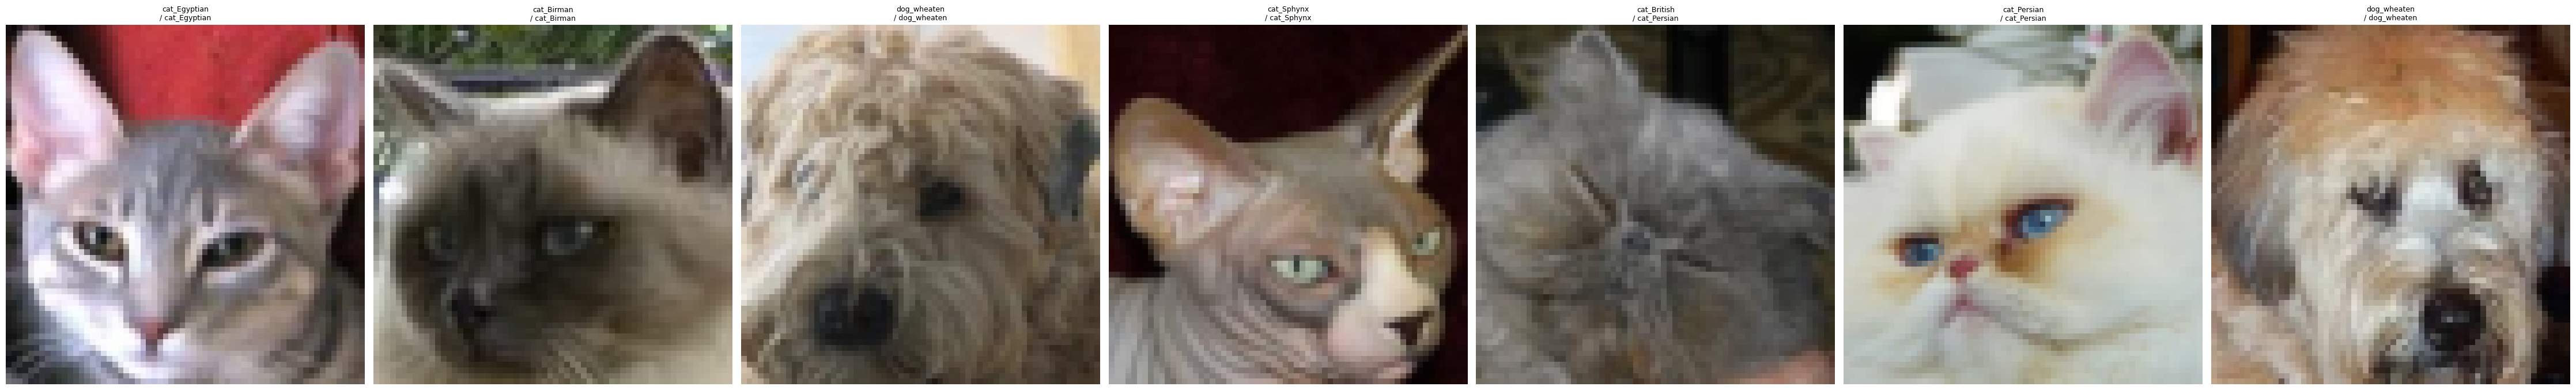

In [20]:
# Примеры предсказаний на тесте: заголовок - "предсказание / правильный ответ"
show = np.random.RandomState(SEED).choice(len(test_idx), 7, replace=False)
display_images([images[test_idx[i]] for i in show],
               titles=[f'{classes[pred[i]]}\n/ {classes[targets[i]]}' for i in show], fontsize=9)

## 11. Итоговая таблица

Ячейка ниже печатает готовую таблицу в формате Markdown — её можно скопировать в `REPORT.md`.

In [21]:
print('| Метрика (Pet Faces, test) | Значение |')
print('|---|---|')
print(f'| Число классов | {num_classes} |')
print(f'| Точность определения породы (top-1) | {breed_acc:.3f} |')
print(f'| Top-3 accuracy | {top3_acc:.3f} |')
print(f'| Кошки против собак (через предсказанную породу) | {binary_from_breed_acc:.3f} |')
print(f'| Кошки против собак (отдельная бинарная сеть) | {binary_net_acc:.3f} |')
print(f'| Базовая модель, validation accuracy | {baseline_val_acc:.3f} |')
print(f'| Лучшая конфигурация при подборе, validation accuracy | {best_val_acc:.3f} |')
print()
print('Лучшая конфигурация:', best_cfg)

| Метрика (Pet Faces, test) | Значение |
|---|---|
| Число классов | 35 |
| Точность определения породы (top-1) | 0.821 |
| Top-3 accuracy | 0.946 |
| Кошки против собак (через предсказанную породу) | 0.984 |
| Кошки против собак (отдельная бинарная сеть) | 0.960 |
| Базовая модель, validation accuracy | 0.665 |
| Лучшая конфигурация при подборе, validation accuracy | 0.702 |

Лучшая конфигурация: {'channels': (32, 64, 128, 256, 512), 'kernel': 3, 'hidden': 128, 'lr': 0.0003, 'dropout': 0.2}
